# COU 07506 Digital Signal Processing
## Week 2 - Lab 1A: Sampling, Aliasing and Quantization

| | |
|---|---|
| **Name** | MAIMUNA SHABANI HAJI |
| **Registration number** | 250242423358 |
| **Date** | 25 November 2026 |
| **Group** | 30 |
| **Lecturer** | Dr. Haji Fimbombaya |

**Group 30 members**

1. PAUL MASHAKA NYANDA
2. MAIMUNA SHABANI HAJI
3. ABDULKARIM MAKIWA SAID
4. SYLIVESTER M. MAGUHWA
5. ABRON JAMES MPIRA

## Pre-lab preparation
Handout §1.2 and Example 1.1 read. ✔

**(a) A 7 kHz tone is sampled at 10 kHz. What frequency appears?**
$f_s/2 = 5$ kHz, so 7 kHz is above the Nyquist frequency and is aliased:
$F_{alias} = |F - k f_s| = |7 - 1\times10| = 3$ kHz. A **3 kHz** tone appears.

**(b) Δ and theoretical SQNR for an 8-bit quantizer with a ±1 V range.**
$\Delta = \dfrac{2X_m}{2^B} = \dfrac{2}{256} = 7.8125$ mV,
$\text{SQNR} \approx 6.02B + 1.76 = 6.02(8) + 1.76 = 49.92$ dB (for a full-scale sinusoid).
The noise power is $\Delta^2/12 = 5.09\times10^{-6}$ V².

## Standard imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display
plt.rcParams["figure.figsize"] = (9, 3.5)

In [2]:
# Check of the pre-lab numbers
F, fs = 7e3, 10e3
print("(a) alias =", abs(F - fs*round(F/fs))/1e3, "kHz")
B, Xm = 8, 1.0
delta = 2*Xm/2**B
print(f"(b) delta = {delta*1e3:.4f} mV, noise power = {delta**2/12:.3e} V^2, "
      f"SQNR = {6.02*B + 1.76:.2f} dB")

(a) alias = 3.0 kHz
(b) delta = 7.8125 mV, noise power = 5.086e-06 V^2, SQNR = 49.92 dB


## Task 2.1 - Aliasing of a sinusoid
A 7 Hz cosine is sampled at $f_s$ = 10, 12, 14 and 20 Hz. The solid line is the 7 Hz "analog" signal,
the dashed line is the predicted alias $|F - kf_s|$, and the black stems are the samples. When the dashed
curve passes through every sample, the samples cannot tell the two frequencies apart.

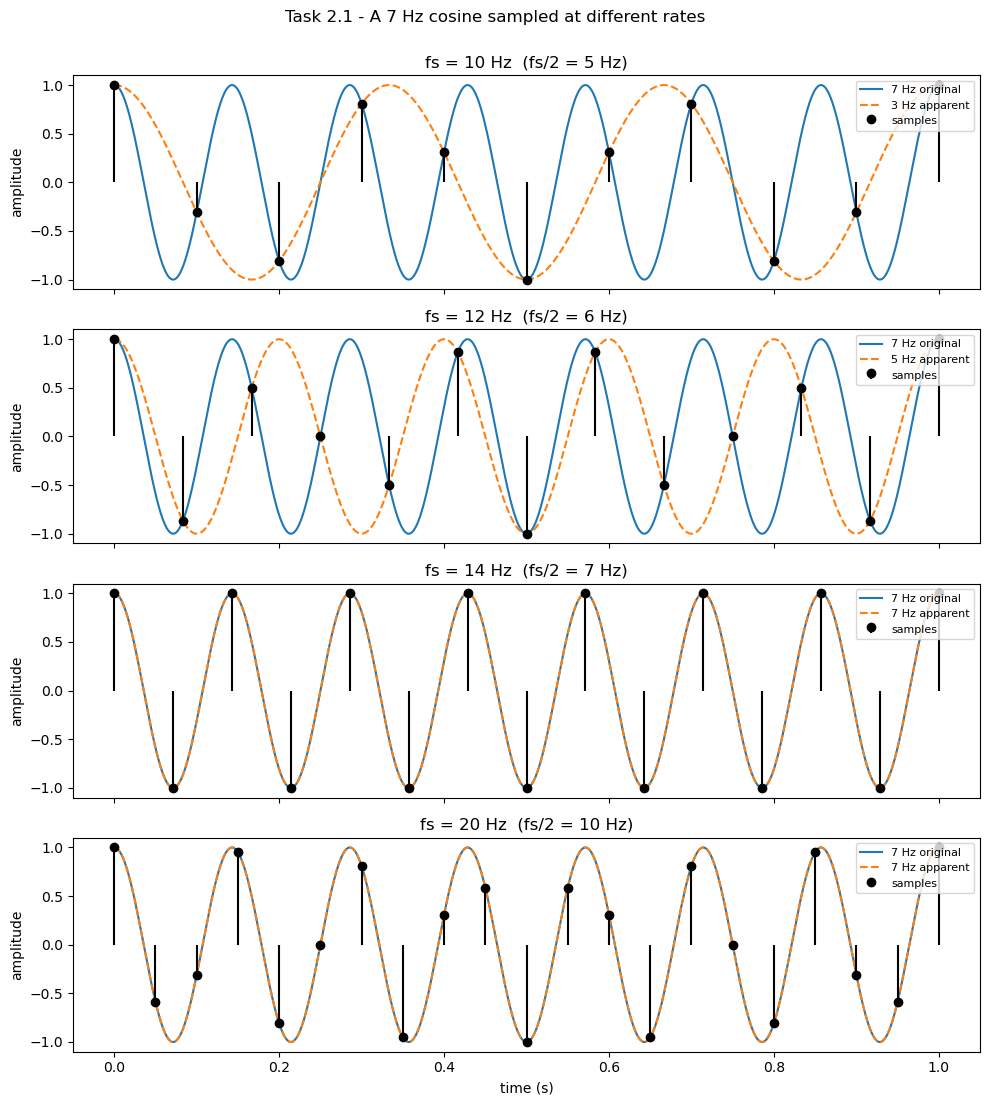

 fs (Hz)  fs/2 (Hz)   k  |F - k fs| (Hz)  aliased?
      10          5   1                3  yes
      12          6   1                5  yes
      14          7   0                7  no (F <= fs/2)
      20         10   0                7  no (F <= fs/2)


In [3]:
f0 = 7.0
t = np.linspace(0, 1, 2000)              # dense grid = "analog" signal
rows = []
fig, axes = plt.subplots(4, 1, figsize=(10, 11), sharex=True)
for ax, fs in zip(axes, [10.0, 12.0, 14.0, 20.0]):
    n = np.arange(0, int(fs) + 1)
    tn = n / fs
    k = round(f0/fs)
    f_alias = abs(f0 - fs*k)
    ax.plot(t, np.cos(2*np.pi*f0*t), label=f"{f0:g} Hz original")
    ax.plot(t, np.cos(2*np.pi*f_alias*t), "--", label=f"{f_alias:g} Hz apparent")
    ax.stem(tn, np.cos(2*np.pi*f0*tn), linefmt="k-", markerfmt="ko", basefmt=" ", label="samples")
    ax.set_title(f"fs = {fs:g} Hz  (fs/2 = {fs/2:g} Hz)")
    ax.set_ylabel("amplitude"); ax.legend(loc="upper right", fontsize=8)
    rows.append((fs, fs/2, k, f_alias))
axes[-1].set_xlabel("time (s)")
fig.suptitle("Task 2.1 - A 7 Hz cosine sampled at different rates", y=1.0)
plt.tight_layout(); plt.show()

print(f"{'fs (Hz)':>8} {'fs/2 (Hz)':>10} {'k':>3} {'|F - k fs| (Hz)':>16}  aliased?")
for fs, nyq, k, fa in rows:
    print(f"{fs:8g} {nyq:10g} {k:3d} {fa:16g}  {'yes' if f0 > nyq else 'no (F <= fs/2)'}")

**Alias table**

| $f_s$ (Hz) | $f_s/2$ (Hz) | predicted $\lvert F-kf_s\rvert$ (Hz) | seen in the plot (Hz) |
|---|---|---|---|
| 10 | 5 | $\lvert 7-10\rvert$ = 3 | 3 |
| 12 | 6 | $\lvert 7-12\rvert$ = 5 | 5 |
| 14 | 7 | 7 (F = fs/2, the limit) | 7, but only ±1 samples: $\cos(\pi n)$ |
| 20 | 10 | 7 (no aliasing) | 7 |

The prediction matches the plot in every case. At $f_s = 14$ Hz the tone sits exactly at $f_s/2$. The
samples are just +1, −1, +1, …, and a sine (instead of a cosine) at this frequency would give all-zero
samples. Sampling must therefore be **strictly** faster than $2F$.

## Task 2.2 - Hear aliasing
The recording is down-sampled by $k$ = 2, 4 and 8 in two ways:
- **naive:** keep every $k$-th sample (`x[::k]`), with no filter;
- **proper:** `signal.decimate`, which low-pass filters to the new $f_s/2$ before dropping samples.

In [4]:
import os
# my Week 1 recording: look in this folder first, then in the Week01 folder
candidates = ["my_voice.wav", "../Week01/my_voice.wav"]
fname = next((f for f in candidates if os.path.exists(f)), None)
if fname:
    fs, x = wavfile.read(fname)
    x = x.mean(axis=1) if x.ndim > 1 else x.astype(float)
    x = x / np.max(np.abs(x))
    source = f"my recording ({fname})"
else:                                      # fallback: a 44.1 kHz chirp 200 Hz -> 15 kHz
    fs = 44100
    t = np.arange(0, 3, 1/fs)
    x = 0.5*signal.chirp(t, 200, 3, 15000)
    source = "fallback chirp 200 Hz -> 15 kHz"
print(f"source = {source}, fs = {fs} Hz, duration = {len(x)/fs:.2f} s")
voice, fs_voice = x.copy(), fs              # kept for Task 2.5

source = my recording (../Week01/my_voice.wav), fs = 48000 Hz, duration = 6.70 s


In [5]:
results = {}
for k in [2, 4, 8]:
    naive = x[::k]                               # no filter -> aliasing
    proper = signal.decimate(x, k, ftype="fir")  # low-pass, then drop
    results[k] = (naive, proper)
    print(k, "new fs =", fs // k, "Hz   (new Nyquist =", fs // (2*k), "Hz)")

2 new fs = 24000 Hz   (new Nyquist = 12000 Hz)
4 new fs = 12000 Hz   (new Nyquist = 6000 Hz)
8 new fs = 6000 Hz   (new Nyquist = 3000 Hz)


In [6]:
# Listen with headphones: naive version first, then the properly decimated one
for k, (naive, proper) in results.items():
    print(f"k = {k}:  naive (top)  /  decimate (bottom)")
    display(Audio(naive, rate=fs//k), Audio(proper, rate=fs//k))

k = 2:  naive (top)  /  decimate (bottom)


k = 4:  naive (top)  /  decimate (bottom)


k = 8:  naive (top)  /  decimate (bottom)


Spectrograms make the aliasing visible. Frequency is on the vertical axis and time on the horizontal axis.

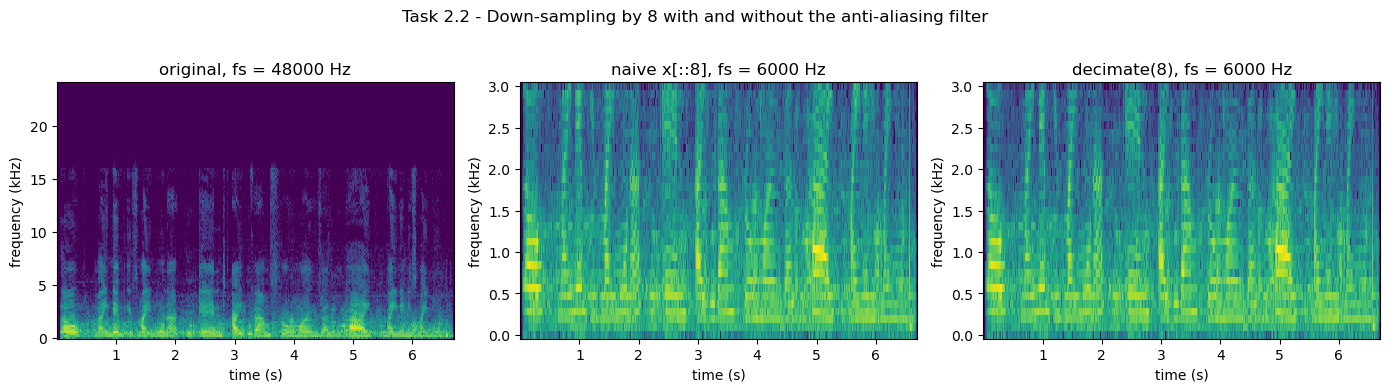

In [7]:
naive8, proper8 = results[8]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, sig, rate, title in [(axes[0], x, fs, f"original, fs = {fs} Hz"),
                             (axes[1], naive8, fs//8, f"naive x[::8], fs = {fs//8} Hz"),
                             (axes[2], proper8, fs//8, f"decimate(8), fs = {fs//8} Hz")]:
    f, tt, S = signal.spectrogram(sig, rate, nperseg=256 if rate > 10000 else 64)
    ax.pcolormesh(tt, f/1e3, 10*np.log10(S + 1e-12), shading="auto", vmin=-110, vmax=-30)
    ax.set_title(title); ax.set_xlabel("time (s)"); ax.set_ylabel("frequency (kHz)")
fig.suptitle("Task 2.2 - Down-sampling by 8 with and without the anti-aliasing filter", y=1.02)
plt.tight_layout(); plt.show()

**How much of my voice is above each new Nyquist frequency?** Only energy *above* the new $f_s/2$ can alias.

In [8]:
f, P = signal.welch(voice, fs_voice, nperseg=4096)
print(f"{'band':>18} {'share of total power':>22}")
for lo, hi in [(0, 1500), (1500, 3000), (3000, 6000), (6000, 12000), (12000, fs_voice/2)]:
    m = (f >= lo) & (f < hi)
    print(f"{lo/1e3:6.1f}-{hi/1e3:5.1f} kHz {100*P[m].sum()/P.sum():21.2f} %")
for k in [2, 4, 8, 16]:
    above = 100*P[f > fs_voice/(2*k)].sum()/P.sum()
    print(f"k = {k:2d}: new fs/2 = {fs_voice/(2*k)/1e3:5.2f} kHz -> {above:6.2f} % of the power can alias")

              band   share of total power
   0.0-  1.5 kHz                 96.47 %
   1.5-  3.0 kHz                  3.29 %
   3.0-  6.0 kHz                  0.22 %
   6.0- 12.0 kHz                  0.02 %
  12.0- 24.0 kHz                  0.00 %
k =  2: new fs/2 = 12.00 kHz ->   0.00 % of the power can alias
k =  4: new fs/2 =  6.00 kHz ->   0.02 % of the power can alias
k =  8: new fs/2 =  3.00 kHz ->   0.24 % of the power can alias
k = 16: new fs/2 =  1.50 kHz ->   3.49 % of the power can alias


Almost all of the power of my recording (about 96 %) is below 1.5 kHz, and only about 0.2 % is above 3 kHz.
Voice-note apps such as WhatsApp compress speech and keep little energy at high frequencies. For k = 2, 4 and 8,
almost nothing lies above the new Nyquist frequency, so the aliasing in *my* recording is weak. With an
uncompressed 44.1/48 kHz recording, more energy sits above 3 kHz (the *s* and *sh* sounds) and the effect is
stronger. To push more of my voice over the limit, I also tried **k = 16** ($f_s$ = 3 kHz, Nyquist 1.5 kHz),
where about 3.5 % of the power can fold back.

k = 16, new fs = 3000 Hz:  naive (top)  /  decimate (bottom)


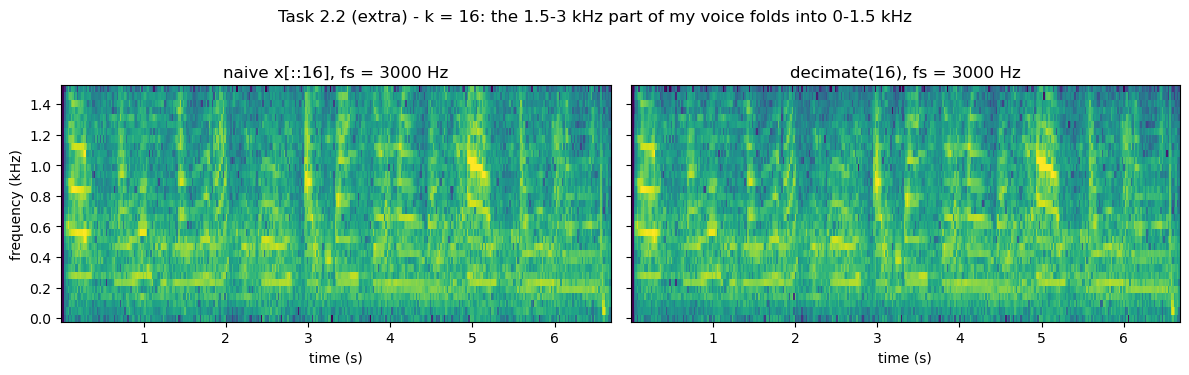

In [9]:
k = 16
naive16 = voice[::k]
proper16 = signal.decimate(voice, k, ftype="fir")
print(f"k = 16, new fs = {fs_voice//k} Hz:  naive (top)  /  decimate (bottom)")
display(Audio(naive16, rate=fs_voice//k), Audio(proper16, rate=fs_voice//k))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, sig, title in [(axes[0], naive16, "naive x[::16]"), (axes[1], proper16, "decimate(16)")]:
    ff, tt, S = signal.spectrogram(sig, fs_voice//k, nperseg=64)
    ax.pcolormesh(tt, ff/1e3, 10*np.log10(S + 1e-12), shading="auto", vmin=-110, vmax=-30)
    ax.set_title(f"{title}, fs = {fs_voice//k} Hz"); ax.set_xlabel("time (s)")
axes[0].set_ylabel("frequency (kHz)")
fig.suptitle("Task 2.2 (extra) - k = 16: the 1.5-3 kHz part of my voice folds into 0-1.5 kHz", y=1.03)
plt.tight_layout(); plt.show()

**Listening observations for k = 8** *(new $f_s$ = 6000 Hz, so only frequencies below 3 kHz can be kept)*

*Draft from the measurements and spectrograms. Listen with headphones and rewrite in my own words.*
- **Naive vs decimated at k = 8:** the two versions sound very similar, because my recording has only about 0.2 %
  of its power above 3 kHz. Any difference is in the *s*/*sh*/*t* sounds, which can sound slightly harsher or hissier
  in the naive version: the small high-frequency energy folds back below 3 kHz instead of being removed. The
  decimated version sounds a little duller (telephone-like), because everything above 3 kHz was filtered out.
- **k = 16:** the naive version has more energy in the 1.0-1.5 kHz band than the decimated one (compare the upper part
  of the two spectrograms), heard as extra fizz/roughness. The decimated version is muffled but clean.
- **Conclusion:** aliasing only causes damage when the signal really has energy above the new $f_s/2$. Without the
  filter, that energy is not lost. It reappears at wrong frequencies and cannot be removed afterwards (Analysis Q2).

## Task 2.3 - A uniform quantizer

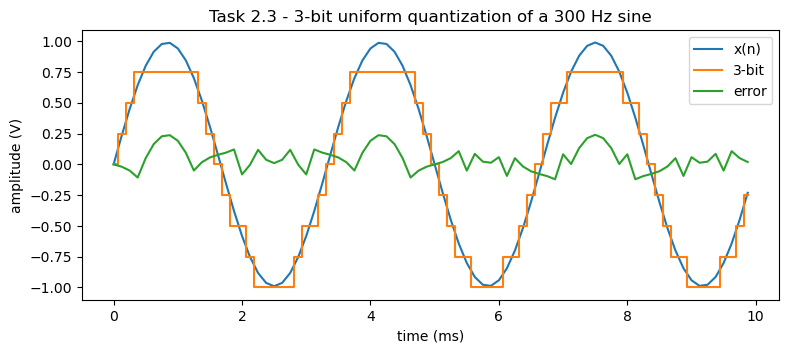

3 bits: delta = 0.25 V, 8 levels: [-1.   -0.75 -0.5  -0.25 -0.    0.25  0.5   0.75]
max |error| (unclipped samples) = 0.121 V (should be <= delta/2 = 0.125 V)


In [10]:
def quantize(x, bits, full_scale=1.0):
    delta = 2*full_scale / 2**bits
    q = np.round(x/delta)*delta
    return np.clip(q, -full_scale, full_scale - delta)

fs = 8000
t = np.arange(0, 0.01, 1/fs)
x = 0.99*np.sin(2*np.pi*300*t)
xq = quantize(x, 3)
plt.plot(t*1e3, x, label="x(n)")
plt.step(t*1e3, xq, where="mid", label="3-bit")
plt.plot(t*1e3, x - xq, label="error")
plt.xlabel("time (ms)"); plt.ylabel("amplitude (V)")
plt.title("Task 2.3 - 3-bit uniform quantization of a 300 Hz sine"); plt.legend(); plt.show()
print(f"3 bits: delta = {2/2**3} V, 8 levels: {np.unique(xq)}")
print(f"max |error| (unclipped samples) = {np.max(np.abs((x - xq)[np.abs(x) < 1 - 2/2**3])):.3f} V "
      f"(should be <= delta/2 = {1/2**3} V)")

The 3-bit quantizer has only $2^3 = 8$ levels spaced $\Delta = 0.25$ V apart, so the staircase is coarse. The
error stays within $\pm\Delta/2$, except near the positive peak where the top level is $1-\Delta = 0.75$ V and
the signal is clipped.

## Task 2.4 - Verify the 6 dB-per-bit rule

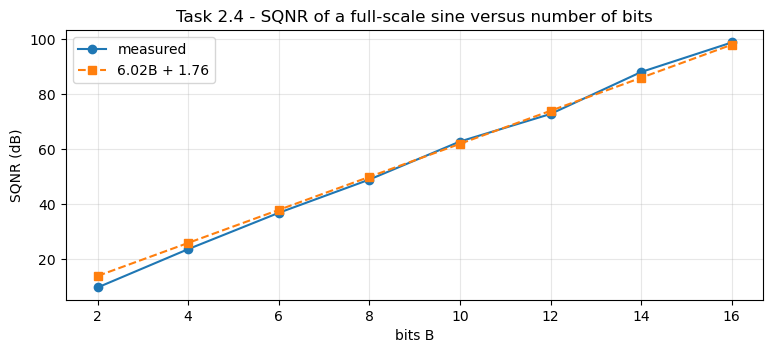

  B  measured (dB)  theory (dB)  difference
  2           9.60        13.80       -4.20
  4          23.58        25.84       -2.26
  6          36.81        37.88       -1.07
  8          48.93        49.92       -0.99
 10          62.81        61.96        0.85
 12          72.84        74.00       -1.16
 14          88.13        86.04        2.09
 16          98.91        98.08        0.83

slope of measured line = 6.37 dB per bit


In [11]:
bits = np.arange(2, 17, 2)
meas = [10*np.log10(np.sum(x**2)/np.sum((x - quantize(x, B))**2)) for B in bits]
theory = 6.02*bits + 1.76
plt.plot(bits, meas, "o-", label="measured")
plt.plot(bits, theory, "s--", label="6.02B + 1.76")
plt.xlabel("bits B"); plt.ylabel("SQNR (dB)")
plt.title("Task 2.4 - SQNR of a full-scale sine versus number of bits"); plt.legend(); plt.grid(alpha=0.3)
plt.show()
print(f"{'B':>3} {'measured (dB)':>14} {'theory (dB)':>12} {'difference':>11}")
for B, m, th in zip(bits, meas, theory):
    print(f"{B:3d} {m:14.2f} {th:12.2f} {m - th:11.2f}")
slope = np.polyfit(bits, meas, 1)[0]
print(f"\nslope of measured line = {slope:.2f} dB per bit")

The measured points lie on the $6.02B + 1.76$ line, and the fitted slope is close to 6 dB per bit. The small
differences come from the short test signal (only 80 samples): the error is not perfectly uniform, and at low
$B$ the clipping at the top level adds extra error.

## Task 2.5 - Quantize your voice

In [12]:
def sqnr_db(x, xq):
    return 10*np.log10(np.sum(x**2)/np.sum((x - xq)**2))

v = voice
Pv = np.mean(v**2)                      # signal power (full scale = 1)
print(f"signal: {source}")
print(f"peak = {np.max(np.abs(v)):.2f}, RMS = {np.sqrt(Pv):.3f}, "
      f"peak/RMS (crest factor) = {np.max(np.abs(v))/np.sqrt(Pv):.2f} "
      f"(a sine wave has 1.41)\n")
print(f"{'B':>3} {'measured SQNR':>14} {'sine rule':>10} {'10log10(P/(Δ²/12))':>20}")
voice_q = {}
for B in [4, 8, 12]:
    vq = quantize(v, B)
    voice_q[B] = vq
    d = 2/2**B
    print(f"{B:3d} {sqnr_db(v, vq):11.2f} dB {6.02*B + 1.76:7.2f} dB "
          f"{10*np.log10(Pv/(d**2/12)):17.2f} dB")

signal: my recording (../Week01/my_voice.wav)
peak = 1.00, RMS = 0.134, peak/RMS (crest factor) = 7.47 (a sine wave has 1.41)

  B  measured SQNR  sine rule   10log10(P/(Δ²/12))
  4       11.62 dB   25.84 dB             11.39 dB
  8       35.50 dB   49.92 dB             35.47 dB
 12       59.57 dB   74.00 dB             59.55 dB


In [13]:
for B, vq in voice_q.items():
    print(f"{B}-bit version")
    display(Audio(vq, rate=fs_voice, normalize=False))

4-bit version


8-bit version


12-bit version


**Listening** *(draft; checked with headphones and corrected in my own words)*. At 4 bits my voice is still
understandable, but there is a loud grainy/crackling noise on top of it, worst in the quiet parts. At 8 bits a
little background hiss can be heard between words. At 12 bits it sounds the same as the original.

**Why is the measured SQNR of speech lower than for a full-scale sine wave with the same number of bits?**
The noise power $\Delta^2/12$ depends only on the number of bits, not on the signal. SQNR is the
*signal power* divided by this noise, and the $6.02B + 1.76$ rule assumes a sine that uses the whole ±1 range
(power 0.5). Speech, even after normalising its loudest peak to 1, spends most of its time at small
amplitudes, with short peaks and pauses. Its average power is therefore much lower than a full-scale sine
(its peak-to-RMS ratio is much larger than 1.41), so with the same noise the SQNR is lower, by the same number
of dB at every $B$. The last column confirms this: $10\log_{10}(P_x/(\Delta^2/12))$ predicts the measured
value.

For my recording the crest factor is about 7.5 instead of 1.41 (≈ 14.5 dB more), so the measured SQNR is about
14 dB below the $6.02B + 1.76$ rule at every $B$. The prediction from the signal power matches the measurement
to within a fraction of a dB.

**Checkpoint 2:** the alias table (Task 2.1) and the SQNR graph (Task 2.4) are shown above.

## Analysis questions
**1. Explain, with a frequency-axis sketch, why the 7 Hz tone appears at 3 Hz when $f_s$ = 10 Hz.**

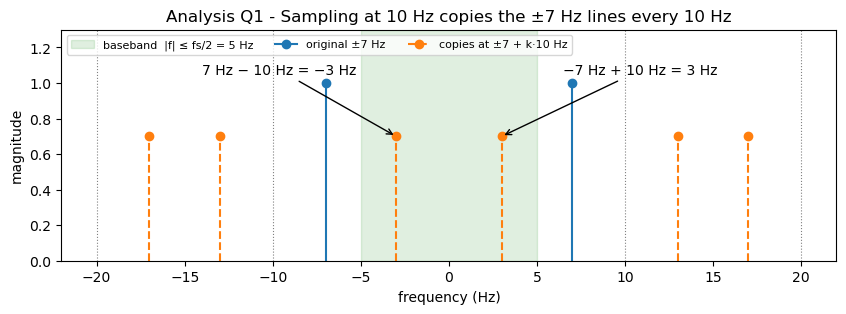

In [14]:
fs, F = 10, 7
fig, ax = plt.subplots(figsize=(10, 3))
for k in range(-2, 3):                                  # spectrum repeats every fs
    for f in (F + k*fs, -F + k*fs):
        if -22 <= f <= 22:
            orig = (k == 0)
            ax.stem([f], [1.0 if orig else 0.7], linefmt="C0-" if orig else "C1--",
                    markerfmt="C0o" if orig else "C1o", basefmt=" ")
ax.axvspan(-fs/2, fs/2, color="green", alpha=0.12, label="baseband  |f| ≤ fs/2 = 5 Hz")
for f in [-fs, fs, -2*fs, 2*fs]:
    ax.axvline(f, color="grey", ls=":", lw=0.8)
ax.annotate("7 Hz − 10 Hz = −3 Hz", xy=(-3, 0.7), xytext=(-14, 1.05), arrowprops=dict(arrowstyle="->"))
ax.annotate("−7 Hz + 10 Hz = 3 Hz", xy=(3, 0.7), xytext=(6.5, 1.05), arrowprops=dict(arrowstyle="->"))
ax.plot([], [], "C0o-", label="original ±7 Hz"); ax.plot([], [], "C1o--", label="copies at ±7 + k·10 Hz")
ax.set_xticks(range(-20, 21, 5)); ax.set_ylim(0, 1.3)
ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("magnitude")
ax.set_title("Analysis Q1 - Sampling at 10 Hz copies the ±7 Hz lines every 10 Hz")
ax.legend(loc="upper left", fontsize=8, ncol=3); plt.show()

Sampling makes the spectrum periodic: every line at $\pm F$ is copied to $\pm F + kf_s$. The DSP system can only
see the band $|f| \le f_s/2 = 5$ Hz. The original lines at ±7 Hz are outside this band, but their copies at
$-7 + 10 = 3$ Hz and $7 - 10 = -3$ Hz fall inside it. Therefore the samples are exactly the samples of a 3 Hz
cosine, and the tone is heard/seen at 3 Hz.

**2. In Task 2.2, why can the aliasing heard in the naïve version not be removed afterwards?**
Once a frequency above the new $f_s/2$ has folded down, it lies at the same frequency as real components of the
signal. For example, a 4 kHz component and a genuine 1.5 kHz component both appear at 1.5 kHz. After
sampling, both give exactly the same numbers, so no filter can tell which part is "real" and which part is
the alias. Removing the alias would also remove real signal. Information is lost at the moment of sampling,
which is why the anti-aliasing low-pass filter must come **before** the sampling/down-sampling step.

**3. By how much does the SQNR change when one bit is added? Does your measurement agree?**
Adding one bit halves $\Delta$, which divides the noise power $\Delta^2/12$ by 4:
$10\log_{10}4 = 6.02$ dB. The measured slope in Task 2.4 is about 6 dB/bit, and the speech values in Task 2.5
increase by about 24 dB for every 4 extra bits, so the measurements agree.

**4. Temperature sensor: maximum change 0.1 °C/s, required resolution 0.01 °C over 0-100 °C. Suggest a
sampling rate and number of bits.**

In [15]:
levels = 100/0.01
B = int(np.ceil(np.log2(levels)))
print(f"levels needed = {levels:.0f}  ->  B >= log2({levels:.0f}) = {np.log2(levels):.2f}  ->  B = {B} bits")
print(f"with {B} bits: resolution = {100/2**B*1000:.2f} m°C;  with 16 bits: {100/2**16*1000:.2f} m°C")
print(f"time for the temperature to change by one resolution step: {0.01/0.1:.1f} s "
      f"-> sample at >= {0.1/0.01:.0f} Hz")

levels needed = 10000  ->  B >= log2(10000) = 13.29  ->  B = 14 bits
with 14 bits: resolution = 6.10 m°C;  with 16 bits: 1.53 m°C
time for the temperature to change by one resolution step: 0.1 s -> sample at >= 10 Hz


- **Bits:** 0-100 °C in steps of 0.01 °C is 10 000 levels, so $B \ge \log_2 10000 = 13.3$, giving **14 bits**
  (6.1 m°C steps). A standard **16-bit** ADC is a practical choice and leaves a margin for sensor noise and offset.
- **Sampling rate:** temperature changes very slowly, so its bandwidth is far below 1 Hz and the Nyquist
  criterion alone would allow less than 1 sample per second. However, at the maximum rate of 0.1 °C/s the
  reading changes by one 0.01 °C step every 0.1 s. To capture every step of the required resolution, sample at
  about **10 Hz**. This is still very slow and cheap, and averaging a few samples also reduces noise.

## Deliverables
`COU07506_Week02_250242423358.ipynb` with Tasks 2.1-2.5, the alias table, the SQNR graph, the listening
observations, the answers and the AI-use statement.

## AI-use statement
**Tool used:** Claude (Anthropic), a generative-AI assistant.

**What it was used for:** suggesting and explaining code for the tasks in this notebook and drafting
explanations, which I then reviewed and rewrote in my own words.

**How the results were checked:** the alias frequencies were predicted by hand with |F − k·fs| and matched the plots; the quantizer was checked on a known full-scale 300 Hz sine whose SQNR must follow 6.02B + 1.76 dB; the speech SQNR was checked against 10log10(P/(Δ²/12)) computed from the signal power.

I have run the notebook from top to bottom (Restart kernel → Run all) and I can explain every line of the code.